# Shadow veto — `off` vs `float32` vs `uint8`

The background model is fixed at its shipped `uint8` state throughout; the only
thing that varies is the **HSV shadow veto** and how its exponentially weighted
RGB background reference is stored:

| Mode | Reference | Veto arithmetic | Reference cost |
| --- | --- | --- | ---: |
| `off` | not allocated | — | 0 B/px |
| `float32` | float32, 3 planes | float | 12 B/px |
| `uint8` | uint8, 3 planes | integer end to end | 3 B/px |

The `uint8` mode is what the C++ and Alif ports implement — they carry no float
reference at all, since 12 B/px of persistent state is 921,600 B at QVGA on a
target that has none to spare. `float32` is kept selectable in Python
(`ShadowConfig.reference_dtype`) precisely so it can be compared here.

Sections mirror `state_dtype_comparison.ipynb`: parameters, a stage grid, CDNET
evaluation, per-frame Sign of Life, and the memory the choice actually buys.

> ### Read the evaluation with two caveats
>
> **1. This dataset is thin.** At 0.1 fps `busStation` yields 4 scorable
> groundtruth frames and `canoe` exactly **1**, and canoe carries **no shadow
> labels at all**. More importantly, over 5–6 frames the EW reference has
> absorbed only ~5 updates at α = 0.1, so `float32` and `uint8` have barely had
> time to diverge. If they agree here that is mostly a statement about the
> sequence length, not about quantisation. Section 4.2 carries the
> full-sequence measurement for that.
>
> **2. CDNET F1 cannot reward this stage.** The protocol scores only pixels
> whose groundtruth is exactly `0` or `255`; shadow is labelled `50` and is
> ignored. So a veto that correctly removes a cast shadow earns nothing, while
> any true foreground it removes with it counts as a miss. **F1 is therefore
> structurally biased towards `off`.** It remains the right metric for
> `float32` vs `uint8` — both veto the same pixels, so the bias cancels — but it
> is not evidence for or against running the veto at all.

In [11]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scr import PipelineConfig, SignOfLifePipeline
from scr.config import (
    BGSConfig,
    BlobConfig,
    DenoiseMethod,
    FeatureConfig,
    FeatureKind,
    Implementation,
    PreprocessConfig,
    ShadowConfig,
    SignOfLifeConfig,
)
from scr.features import ShadowSuppressor
from evaluate import EvaluationResult, accumulate_counts, frame_number, index_masks
from IPython.display import Markdown, display

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp"}

## 1. Parameters

Everything is shared across the three arms except `SHADOW_MODES`. The model is
pinned to `state_dtype="uint8"` — this notebook varies the veto, not the model
(`state_dtype_comparison.ipynb` covers that axis).

`DATASET_ROOT` is the pre-built QVGA 0.1-fps tree, so `RESIZE` stays `None` and
the pipeline runs at the tree's own 320×240.

In [12]:
# ---- Dataset -------------------------------------------------------------
DATASET_ROOT = Path("data_0_1fps_qvga")   # already QVGA -> RESIZE stays None
CASES = ["busStation", "canoe"]
RESIZE = None

# ---- The comparison axis -------------------------------------------------
IMPLEMENTATION = Implementation.NATIVE     # pure-NumPy path, mirrors the ports
SHADOW_MODES = {
    "off": ShadowConfig(enabled=False, implementation=IMPLEMENTATION),
    "float32": ShadowConfig(
        enabled=True, reference_dtype="float32", implementation=IMPLEMENTATION
    ),
    "uint8": ShadowConfig(
        enabled=True, reference_dtype="uint8", implementation=IMPLEMENTATION
    ),
}
REFERENCE_MODE = "float32"     # the arm the others are compared against

# ---- Layer 0: preprocessing ----------------------------------------------
DENOISE = DenoiseMethod.GAUSSIAN

# ---- Layer 1: background model (fixed -- not the axis under test) --------
BACKEND = "running_gaussian"
ALPHA = 0.10
MODEL_STATE_DTYPE = "uint8"     # the shipped state; 2 B/px

# ---- Layer 3: morphology + area gate -------------------------------------
BLOB = BlobConfig(
    min_area=150, open_kernel=3, close_kernel=7, implementation=IMPLEMENTATION
)
SOL_AREA_THRESHOLD = 500

# ---- Visualisation / scoring ---------------------------------------------
GRID_MAX_FRAMES = 5
FG_THRESHOLD = 127

# Categorical slots 1-3 of the reference data-viz palette, validated for
# colourblind separation on all pairs.
COLOURS = {"off": "#2a78d6", "float32": "#eb6834", "uint8": "#1baf7a"}
AGREE_FG = "#8a8880"      # both arms called it foreground
ONLY_REFERENCE = "#2a78d6"  # float32 only -- foreground uint8 dropped
ONLY_CANDIDATE = "#e34948"  # uint8 only   -- foreground uint8 added


def build_config(shadow: ShadowConfig) -> PipelineConfig:
    """Assemble the shared PipelineConfig for one shadow mode."""
    return PipelineConfig(
        preprocess=PreprocessConfig(resize=RESIZE, denoise=DENOISE),
        feature=FeatureConfig(kind=FeatureKind.GRAY),
        shadow=shadow,
        bgs=BGSConfig(
            backend=BACKEND,
            learning_rate=ALPHA,
            implementation=IMPLEMENTATION,
            backend_params={"state_dtype": MODEL_STATE_DTYPE},
        ),
        blob=BLOB,
        sign_of_life=SignOfLifeConfig(area_threshold=SOL_AREA_THRESHOLD),
    )


print("Model :", BACKEND, f"(alpha={ALPHA}, state={MODEL_STATE_DTYPE})")
print("Arms  :", " | ".join(f"{k} ({v.reference_bytes_per_pixel} B/px)"
                            for k, v in SHADOW_MODES.items()))
print("Input :", DATASET_ROOT, "->", CASES)

Model : running_gaussian (alpha=0.1, state=uint8)
Arms  : off (0 B/px) | float32 (12 B/px) | uint8 (3 B/px)
Input : data_0_1fps_qvga -> ['busStation', 'canoe']


## 2. Run the three arms

Each arm sees the **same decoded frame** in the same order, so every difference
downstream comes from the veto alone. Alongside the pipeline output we snapshot
each arm's own shadow map — the veto is the subject here, so it is worth seeing
directly and not only through its effect on the mask.

The veto compares against the reference as of the *previous* frame, so the
background estimate is captured **before** `process()` and fed to a
`ShadowSuppressor` built from the same config, exactly as
`pipeline_experiments.ipynb` does.

In [13]:
def discover_frames(case: str) -> list[Path]:
    directory = DATASET_ROOT / case / "input"
    return sorted(p for p in directory.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES)


def run_case(case: str) -> tuple[list[dict], dict]:
    """Run every shadow mode over one case in lockstep on identical frames."""
    pipelines = {name: SignOfLifePipeline.from_config(build_config(cfg))
                 for name, cfg in SHADOW_MODES.items()}
    suppressors = {name: ShadowSuppressor(cfg) for name, cfg in SHADOW_MODES.items()}
    records: list[dict] = []

    for path in discover_frames(case):
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is None:
            continue
        record = {"number": frame_number(path), "name": path.name}
        for name, pipeline in pipelines.items():
            background = pipeline.model.background_bgr   # state after previous frame
            result = pipeline.process(image)
            record[name] = {
                "foreground": result.foreground,
                "filtered": result.filtered_mask,
                "blobs": result.blobs,
                "sign_of_life": result.sign_of_life,
                # Disabled arms return an all-zero map, so the column is still
                # drawable and obviously empty rather than missing.
                "shadow": suppressors[name].shadow_mask(result.frame, background),
            }
        record["input"] = result.frame.bgr    # identical across arms (Layer 0)
        records.append(record)
    return records, pipelines


results, pipelines = {}, {}
for case in CASES:
    results[case], pipelines[case] = run_case(case)
    height, width = results[case][0]["input"].shape[:2]
    print(f"{case}: {len(results[case])} frames x {len(SHADOW_MODES)} arms at {width}x{height}")

busStation: 6 frames x 3 arms at 320x240
canoe: 5 frames x 3 arms at 320x240


## 3. Stage grid per case

One row per sampled frame.

| Column | Content |
| --- | --- |
| **Input** | Preprocessed frame, identical for all arms |
| **Shadow map `float32` / `uint8`** | Pixels each veto would remove (white) — the two arms' actual decisions, side by side |
| **Foreground `off` / `float32` / `uint8`** | Model output after that arm's veto |
| **Disagreement** | Where the `float32` and `uint8` foregrounds differ |

In the last column grey is foreground both arms agree on, blue is foreground
only `float32` kept, red is foreground only `uint8` kept. On this sequence
length the column is expected to be nearly empty — see the caveat at the top.

In [14]:
COLUMN_TITLES = [
    "Input",
    "Shadow map: float32",
    "Shadow map: uint8",
    "Foreground: off",
    "Foreground: float32",
    "Foreground: uint8",
    "float32 vs uint8",
]


def to_rgb(hex_colour: str) -> np.ndarray:
    hex_colour = hex_colour.lstrip("#")
    return np.array([int(hex_colour[i:i + 2], 16) for i in (0, 2, 4)], dtype=np.uint8)


def disagreement_map(reference: np.ndarray, candidate: np.ndarray) -> np.ndarray:
    """Colour each pixel by which arm called it foreground."""
    ref = reference > FG_THRESHOLD
    cand = candidate > FG_THRESHOLD
    canvas = np.full((*ref.shape, 3), 255, dtype=np.uint8)
    canvas[ref & cand] = to_rgb(AGREE_FG)
    canvas[ref & ~cand] = to_rgb(ONLY_REFERENCE)
    canvas[~ref & cand] = to_rgb(ONLY_CANDIDATE)
    return canvas


def sample_rows(records: list[dict], k: int) -> list[dict]:
    if len(records) <= k:
        return records
    index = np.linspace(0, len(records) - 1, k).round().astype(int)
    return [records[i] for i in index]


def show_grid(case: str, records: list[dict]) -> None:
    rows = sample_rows(records, GRID_MAX_FRAMES)
    fig, axes = plt.subplots(len(rows), len(COLUMN_TITLES),
                             figsize=(20, 2.9 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, record in enumerate(rows):
        panels = [
            record["input"][:, :, ::-1],                # BGR -> RGB
            record["float32"]["shadow"],
            record["uint8"]["shadow"],
            record["off"]["foreground"],
            record["float32"]["foreground"],
            record["uint8"]["foreground"],
            disagreement_map(record["float32"]["foreground"],
                             record["uint8"]["foreground"]),
        ]
        for c, image in enumerate(panels):
            ax = axes[r][c]
            if image.ndim == 3:
                ax.imshow(image)
            else:
                ax.imshow(image, cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(COLUMN_TITLES[c], fontsize=10)
            if c == 0:
                ax.set_ylabel(f"frame #{record['number']}", fontsize=10)
    handles = [
        plt.Line2D([], [], marker="s", linestyle="", markersize=9,
                   markerfacecolor=colour, markeredgecolor="none", label=label)
        for colour, label in (
            (AGREE_FG, "both arms"),
            (ONLY_REFERENCE, "float32 only"),
            (ONLY_CANDIDATE, "uint8 only"),
        )
    ]
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
               fontsize=10, bbox_to_anchor=(0.5, -0.015))
    fig.suptitle(f"{case} — shadow veto off / float32 / uint8 "
                 f"(model fixed at uint8, alpha={ALPHA})", fontsize=13)
    fig.tight_layout()
    plt.show()

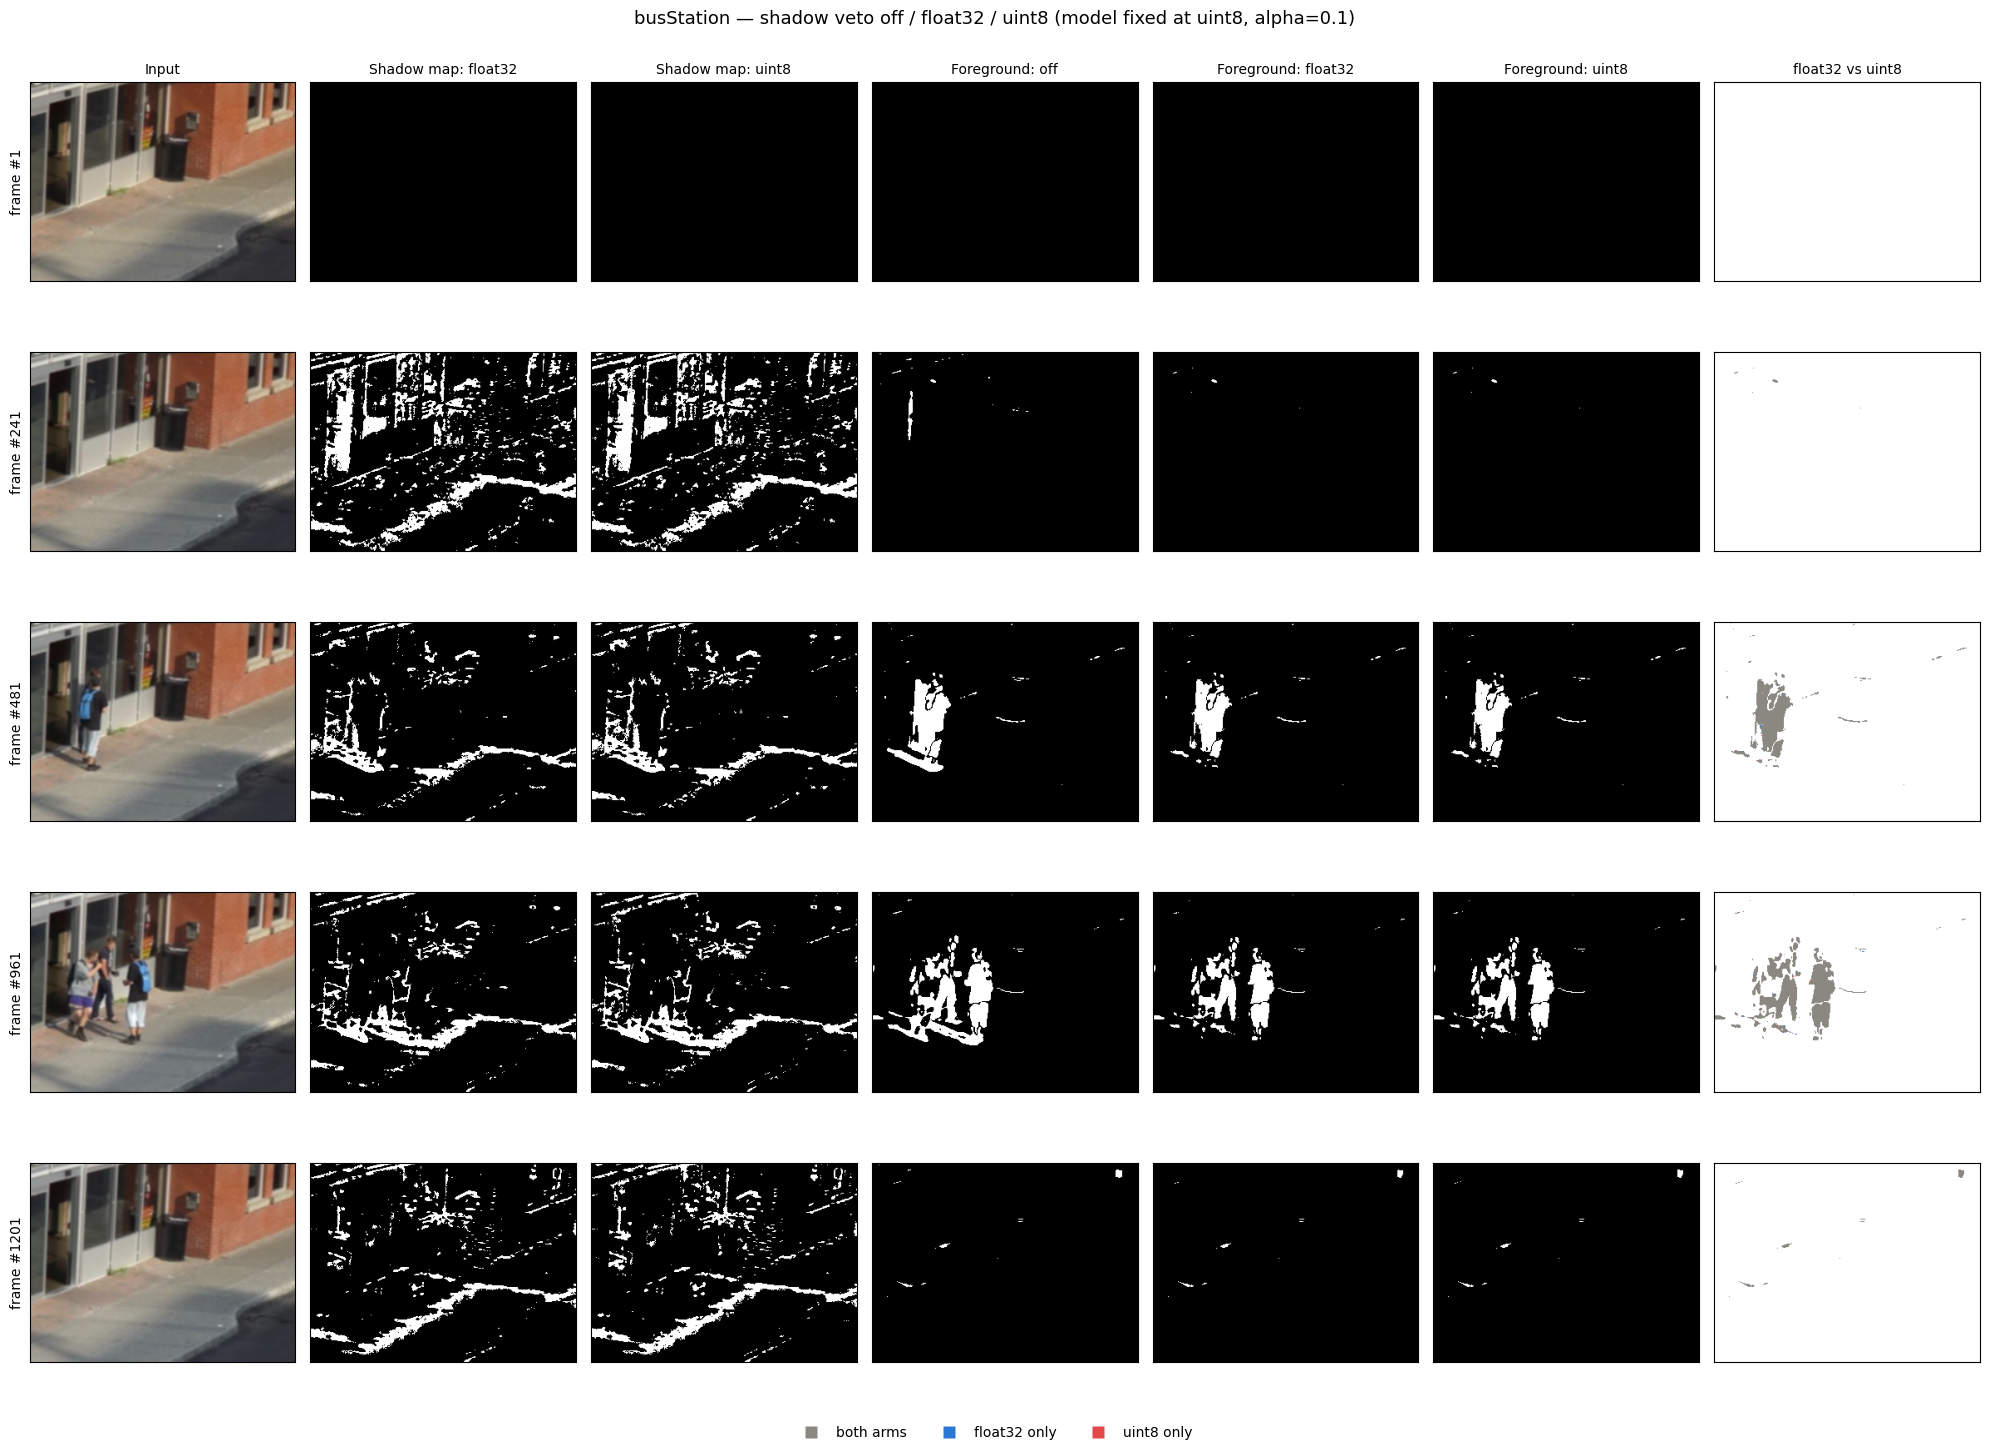

In [15]:
show_grid('busStation', results['busStation'])

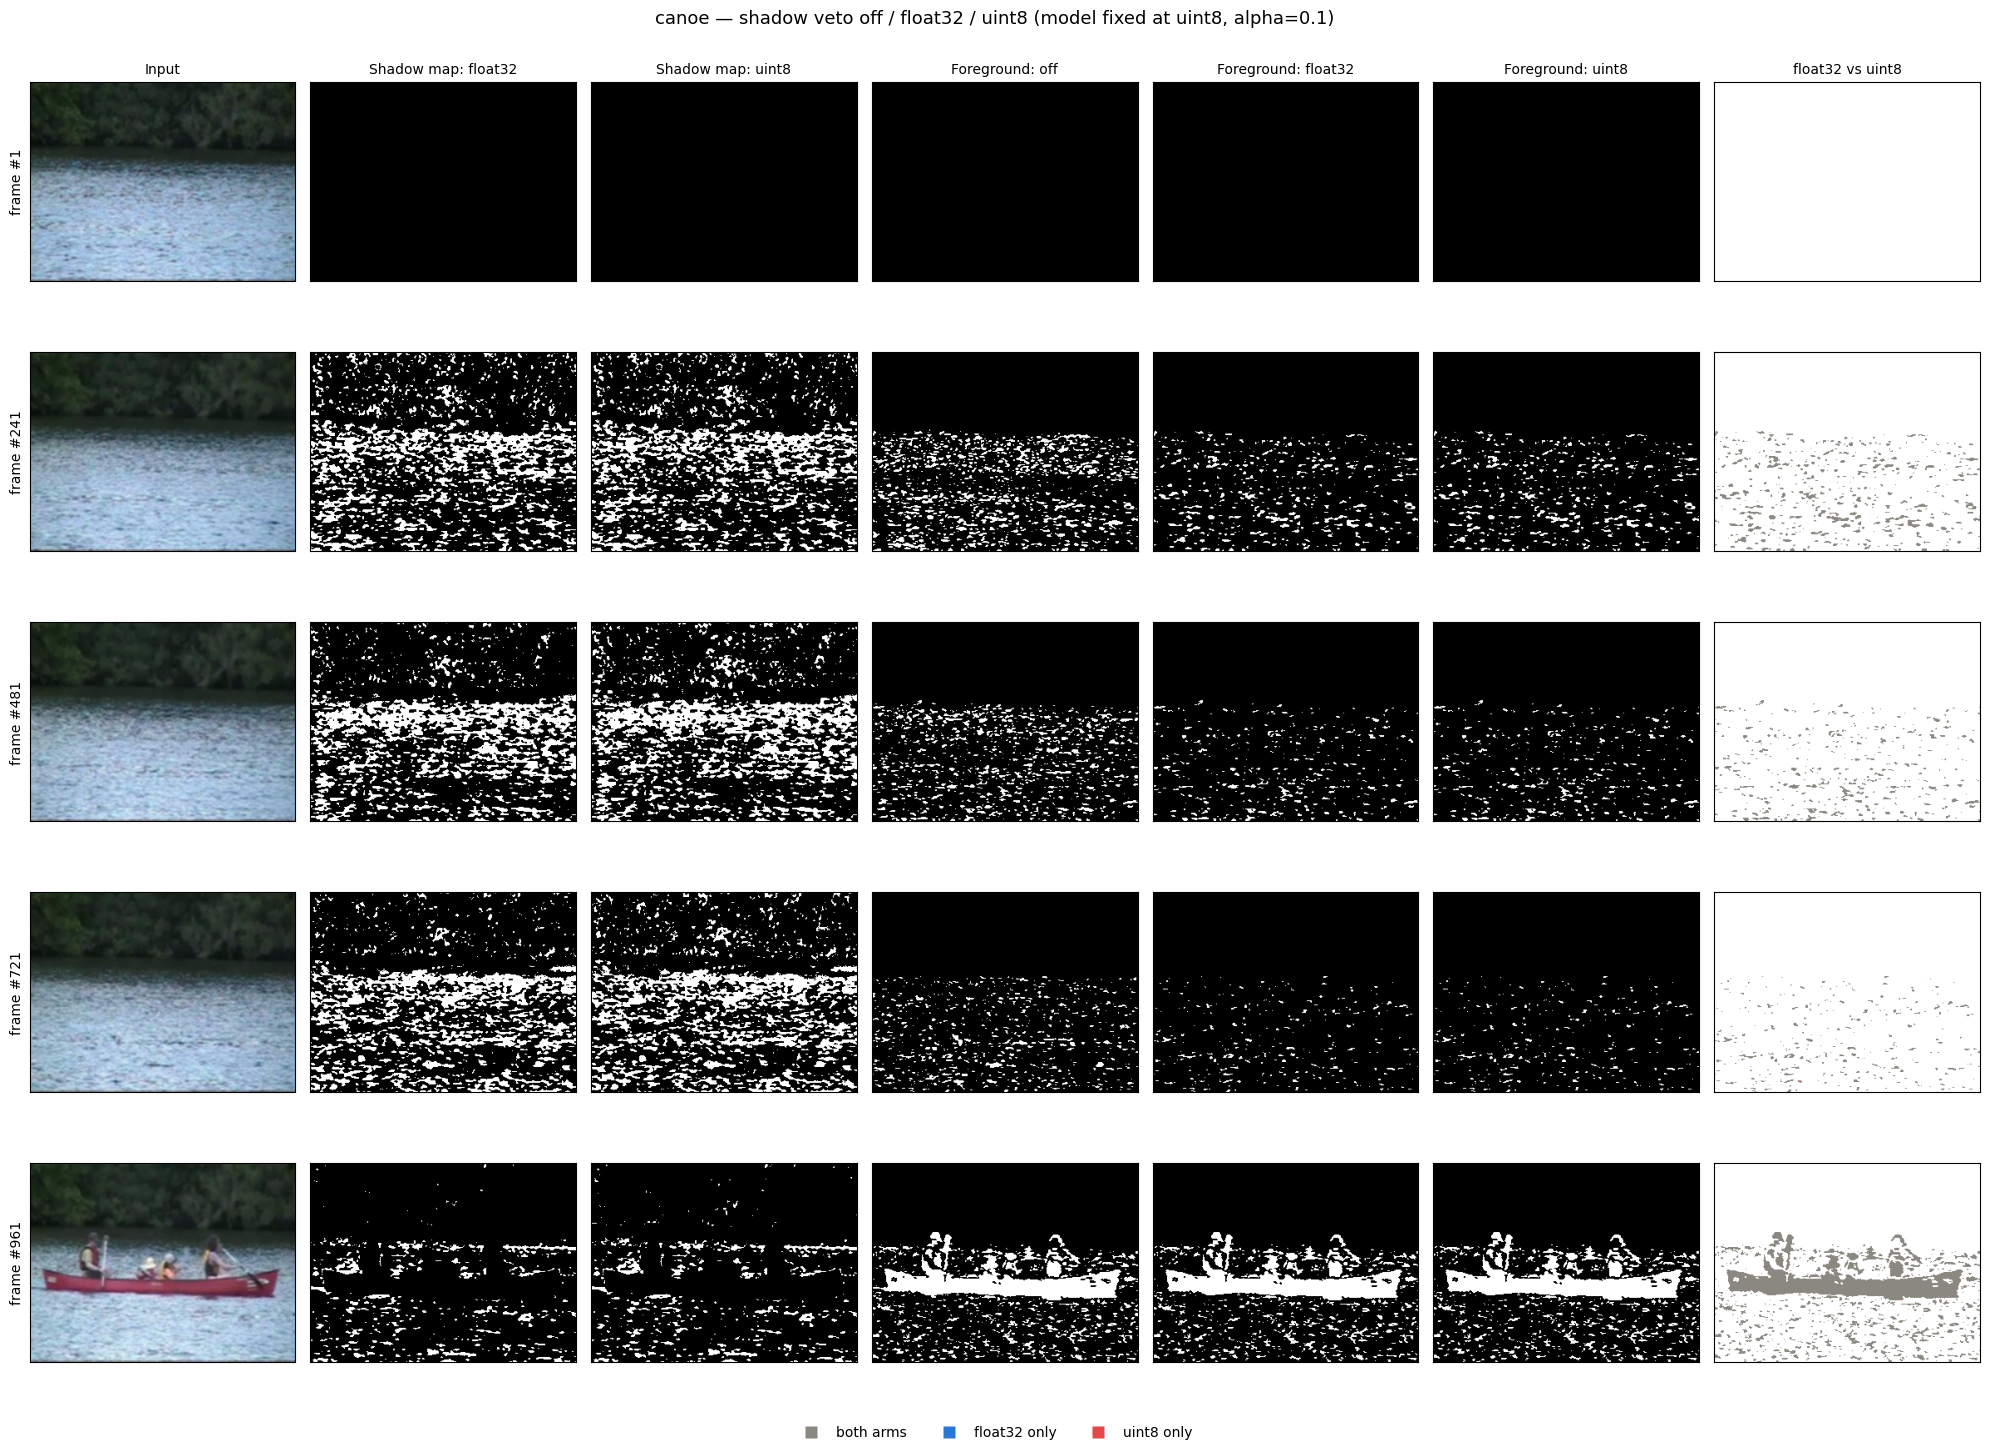

In [16]:
show_grid('canoe', results['canoe'])

## 3.1 Output masks

The grid above stops at the model's foreground. What the pipeline actually
emits is the **filtered mask** — foreground after opening, closing and the area
gate — and that is what the blobs and the Sign-of-Life flag are derived from.
Morphology is not a neutral pass-through: it closes the holes the veto punches
in an object and can delete a region the veto shrank below `min_area`
(`150 px`), so a difference visible in the foreground may vanish here, or
the reverse.

Both meaningful comparisons are drawn: `off` against `float32` isolates what the
veto does at all, and `float32` against `uint8` isolates what quantising its
reference costs. Colours as before — grey where both arms agree, and the
left-hand arm of each pair in blue, the right-hand in red.

In [17]:
OUTPUT_COLUMN_TITLES = [
    "Input",
    "Output: off",
    "Output: float32",
    "Output: uint8",
    "off vs float32",
    "float32 vs uint8",
]


def show_output_grid(case: str, records: list[dict]) -> None:
    """Final (post-morphology, area-gated) masks for each arm, plus the deltas."""
    rows = sample_rows(records, GRID_MAX_FRAMES)
    fig, axes = plt.subplots(len(rows), len(OUTPUT_COLUMN_TITLES),
                             figsize=(17, 2.9 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, record in enumerate(rows):
        panels = [
            record["input"][:, :, ::-1],
            record["off"]["filtered"],
            record["float32"]["filtered"],
            record["uint8"]["filtered"],
            disagreement_map(record["off"]["filtered"],
                             record["float32"]["filtered"]),
            disagreement_map(record["float32"]["filtered"],
                             record["uint8"]["filtered"]),
        ]
        for c, image in enumerate(panels):
            ax = axes[r][c]
            if image.ndim == 3:
                ax.imshow(image)
            else:
                ax.imshow(image, cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(OUTPUT_COLUMN_TITLES[c], fontsize=10)
            if c == 0:
                ax.set_ylabel(f"frame #{record['number']}", fontsize=10)
    handles = [
        plt.Line2D([], [], marker="s", linestyle="", markersize=9,
                   markerfacecolor=colour, markeredgecolor="none", label=label)
        for colour, label in (
            (AGREE_FG, "both arms"),
            (ONLY_REFERENCE, "left arm only (off / float32)"),
            (ONLY_CANDIDATE, "right arm only (float32 / uint8)"),
        )
    ]
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
               fontsize=10, bbox_to_anchor=(0.5, -0.015))
    fig.suptitle(f"{case} — pipeline output mask by shadow mode "
                 f"(after morphology + {BLOB.min_area} px area gate)", fontsize=13)
    fig.tight_layout()
    plt.show()

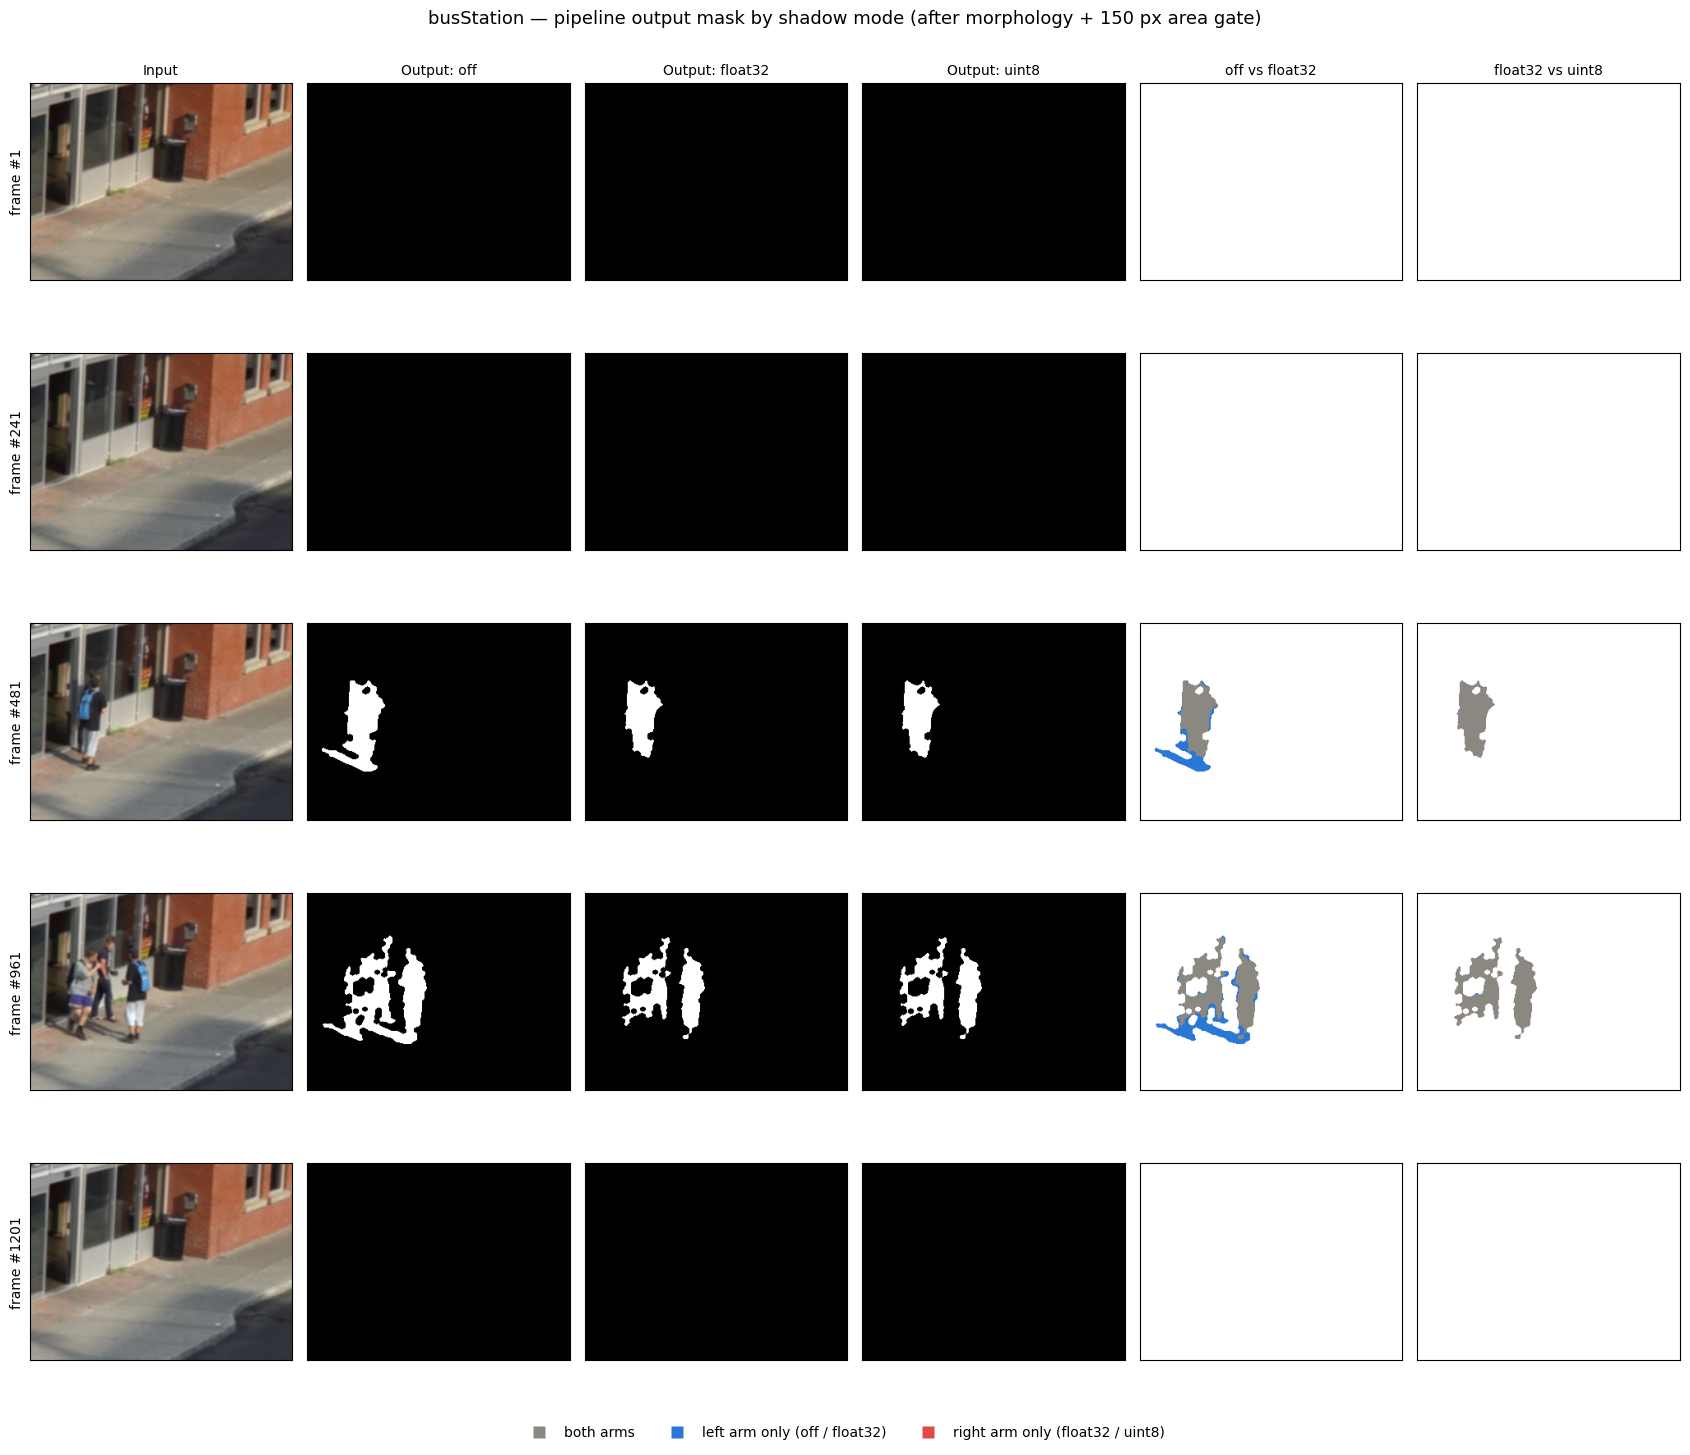

In [18]:
show_output_grid('busStation', results['busStation'])

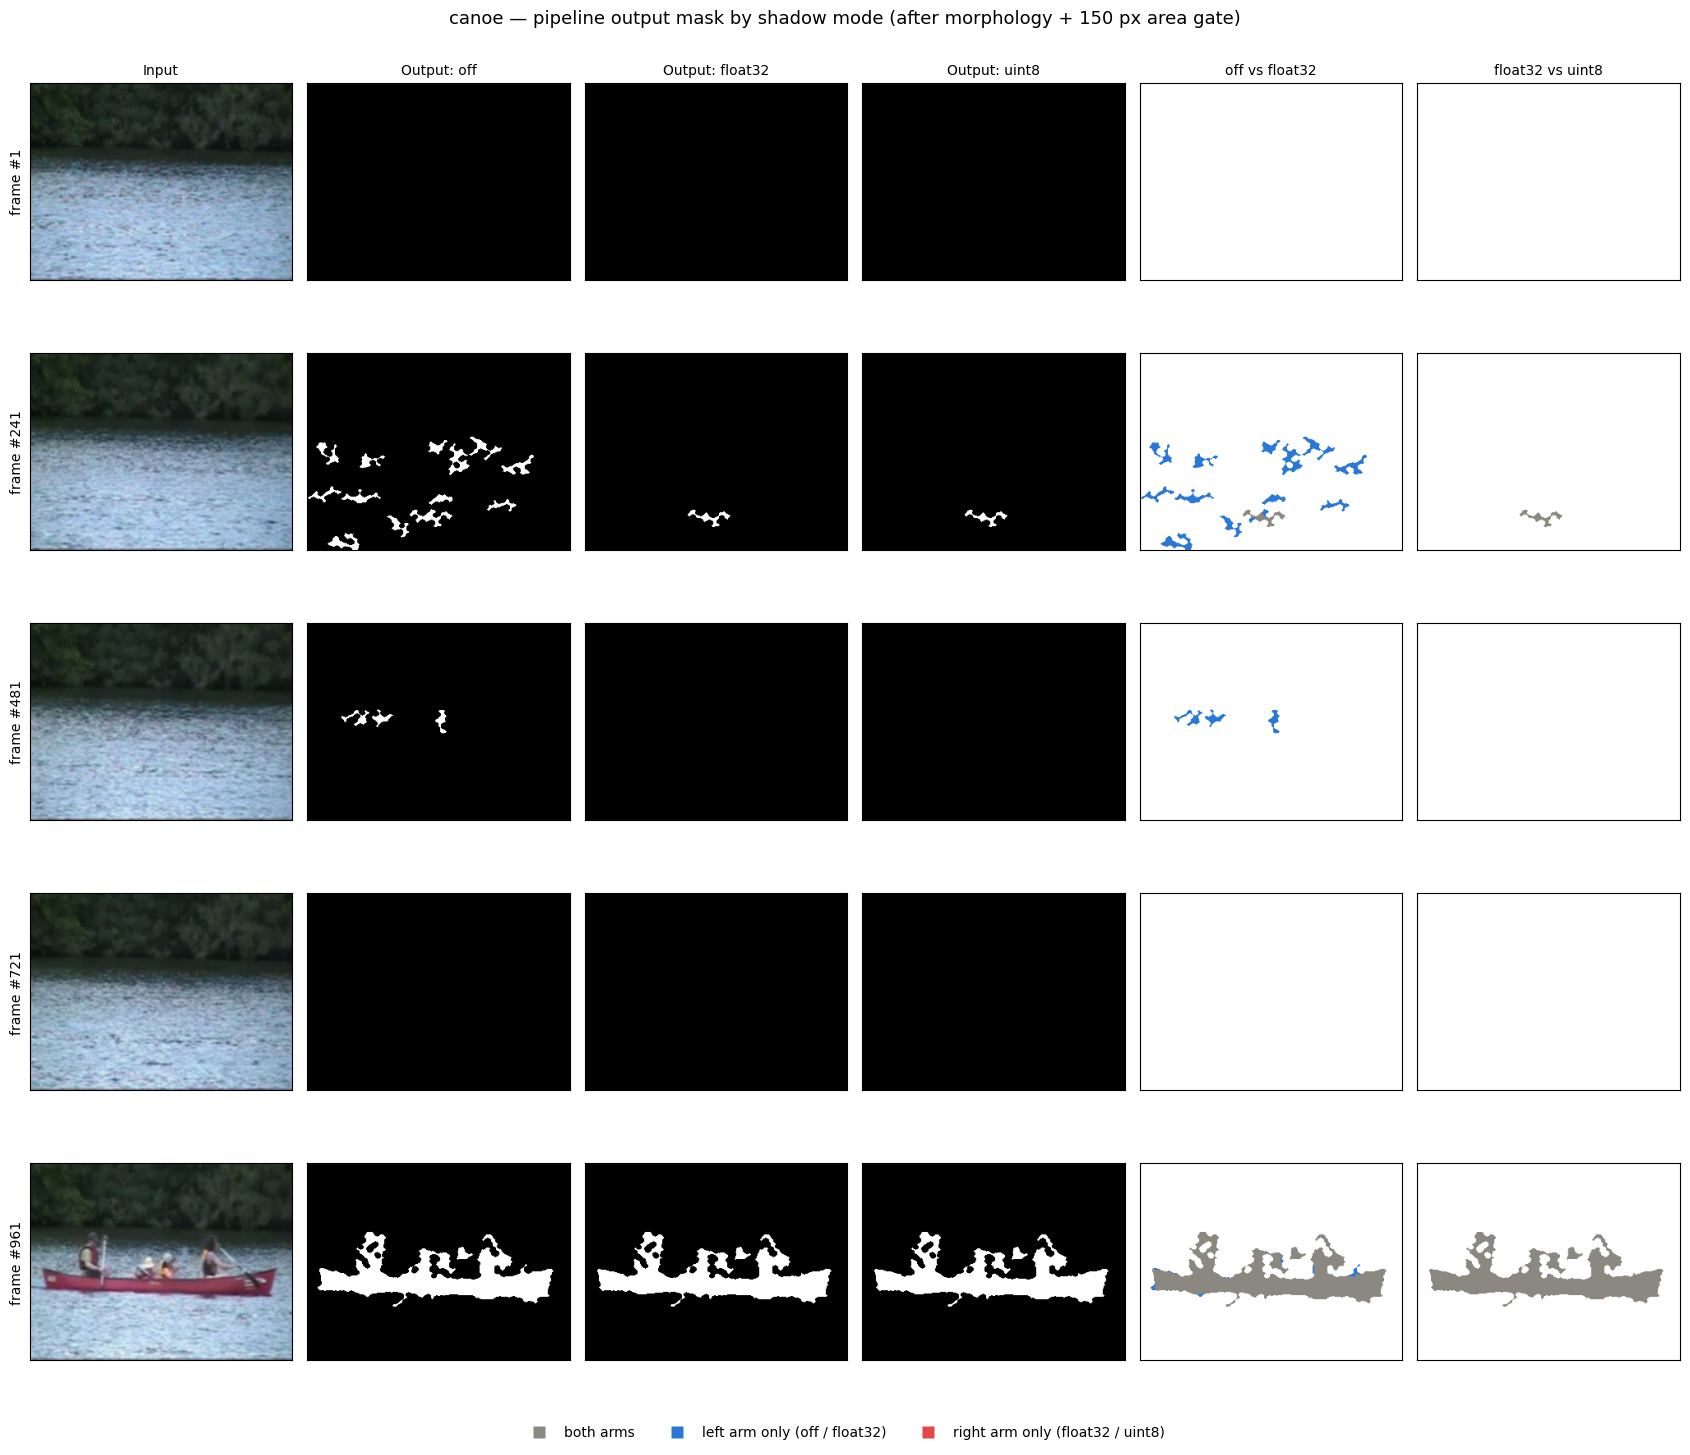

In [19]:
show_output_grid('canoe', results['canoe'])

### 3.1.1 What the masks weigh

The panels show *where* the modes differ; this table shows *how much*. Areas are
in pixels, averaged over the sequence, so the veto's cost is readable as a
number rather than inferred from thumbnails.

`largest blob` is the one that decides the Sign-of-Life flag against the
`500 px` threshold — the column to watch, since a veto that trims a region
below it changes the pipeline's answer, while one that merely thins a mask does
not.

In [20]:
rows = []
for case in CASES:
    for mode in SHADOW_MODES:
        foreground = np.mean([(r[mode]["foreground"] > FG_THRESHOLD).sum()
                              for r in results[case]])
        filtered = np.mean([(r[mode]["filtered"] > FG_THRESHOLD).sum()
                            for r in results[case]])
        largest = np.mean([max((b.area for b in r[mode]["blobs"]), default=0)
                           for r in results[case]])
        blobs = np.mean([len(r[mode]["blobs"]) for r in results[case]])
        rows.append({
            "case": case,
            "shadow mode": mode,
            "mean foreground px": foreground,
            "mean output px": filtered,
            "mean blobs": blobs,
            "mean largest blob px": largest,
        })
areas = pd.DataFrame(rows)
display(
    areas.style.format({
        "mean foreground px": "{:,.0f}",
        "mean output px": "{:,.0f}",
        "mean blobs": "{:.2f}",
        "mean largest blob px": "{:,.0f}",
    }).hide(axis="index").background_gradient(
        subset=["mean output px"], cmap="Blues"
    )
)

# Per-frame output-mask agreement, the pixel-level counterpart of the
# Sign-of-Life agreement in section 5.
rows = []
for case in CASES:
    for mode in SHADOW_MODES:
        differing = np.mean([
            ((r[mode]["filtered"] > FG_THRESHOLD)
             != (r[REFERENCE_MODE]["filtered"] > FG_THRESHOLD)).mean()
            for r in results[case]
        ])
        rows.append({"case": case, "shadow mode": mode,
                     f"output px differing vs {REFERENCE_MODE}": differing})
display(
    pd.DataFrame(rows).style.format(
        {f"output px differing vs {REFERENCE_MODE}": "{:.4%}"}
    ).hide(axis="index")
)

case,shadow mode,mean foreground px,mean output px,mean blobs,mean largest blob px
busStation,off,"2,286","2,228",0.50,"2,228"
busStation,float32,"1,690","1,565",0.67,"1,246"
busStation,uint8,"1,689","1,588",0.67,"1,268"
canoe,off,"6,221","2,788",3.60,"2,088"
canoe,float32,"4,033","2,025",0.60,"1,992"
canoe,uint8,"4,034","2,025",0.60,"1,992"


case,shadow mode,output px differing vs float32
busStation,off,0.8626%
busStation,float32,0.0000%
busStation,uint8,0.0395%
canoe,off,0.9940%
canoe,float32,0.0000%
canoe,uint8,0.0013%


## 4. Evaluation

Scored against the CDNET groundtruth under the standard protocol: only pixels
whose groundtruth is exactly `0` or `255` count, so shadow (50), unknown (170)
and outside-ROI (85) are ignored and frames with none of them drop out.

**On this tree that leaves 4 scorable frames for busStation and 1 for canoe.**
The `eval frames` column below is the honest denominator; treat the numbers as
indicative and read section 4.2 for the full-sequence result.

In [21]:
def evaluate_case(case: str, records: list[dict], mode: str, mask_key: str) -> dict:
    groundtruth = index_masks(DATASET_ROOT / case / "groundtruth")
    tp = fp = fn = tn = frames = 0
    for record in records:
        number = record["number"]
        if number not in groundtruth:
            continue
        gt = cv2.imread(str(groundtruth[number]), cv2.IMREAD_GRAYSCALE)
        counts = accumulate_counts(gt, record[mode][mask_key], FG_THRESHOLD)
        if sum(counts) == 0:
            continue
        tp, fp, fn, tn = tp + counts[0], fp + counts[1], fn + counts[2], tn + counts[3]
        frames += 1
    result = EvaluationResult.from_counts(tp, fp, fn, tn, frames)
    return {
        "case": case,
        "mask": mask_key,
        "shadow mode": mode,
        "eval frames": result.frames,
        "precision": result.precision,
        "recall": result.recall,
        "F-measure": result.f_measure,
        "IoU": result.iou,
    }


scores = pd.DataFrame([
    evaluate_case(case, results[case], mode, mask_key)
    for case in CASES
    for mask_key in ("foreground", "filtered")
    for mode in SHADOW_MODES
])
display(
    scores.style.format(
        {"precision": "{:.3f}", "recall": "{:.3f}", "F-measure": "{:.3f}", "IoU": "{:.3f}"}
    ).hide(axis="index").background_gradient(
        subset=["F-measure"], cmap="RdYlGn", vmin=0, vmax=1
    )
)

case,mask,shadow mode,eval frames,precision,recall,F-measure,IoU
busStation,foreground,off,4,0.841,0.681,0.752,0.603
busStation,foreground,float32,4,0.874,0.620,0.726,0.569
busStation,foreground,uint8,4,0.873,0.621,0.726,0.570
busStation,filtered,off,4,0.975,0.765,0.857,0.750
busStation,filtered,float32,4,0.994,0.673,0.803,0.670
busStation,filtered,uint8,4,0.994,0.685,0.811,0.682
canoe,foreground,off,1,0.594,0.861,0.703,0.543
canoe,foreground,float32,1,0.610,0.860,0.714,0.555
canoe,foreground,uint8,1,0.610,0.860,0.714,0.555
canoe,filtered,off,1,0.913,0.932,0.922,0.856


### 4.1 `uint8` against the `float32` reference

The comparison this notebook exists for. Both veto arms remove the same *kind*
of pixel, so the metric's blindness to shadow labels cancels between them and
the delta is meaningful in a way the `off` row is not.

Bars are `uint8 − float32`; left of zero is a regression.

case,mask,precision,recall,F-measure,IoU
busStation,filtered,+0.0001,+0.0115,+0.0082,+0.0114
busStation,foreground,-0.0008,+0.0006,+0.0001,+0.0001
canoe,filtered,-0.0002,+0.0000,-0.0001,-0.0002
canoe,foreground,-0.0001,+0.0000,-0.0000,-0.0000


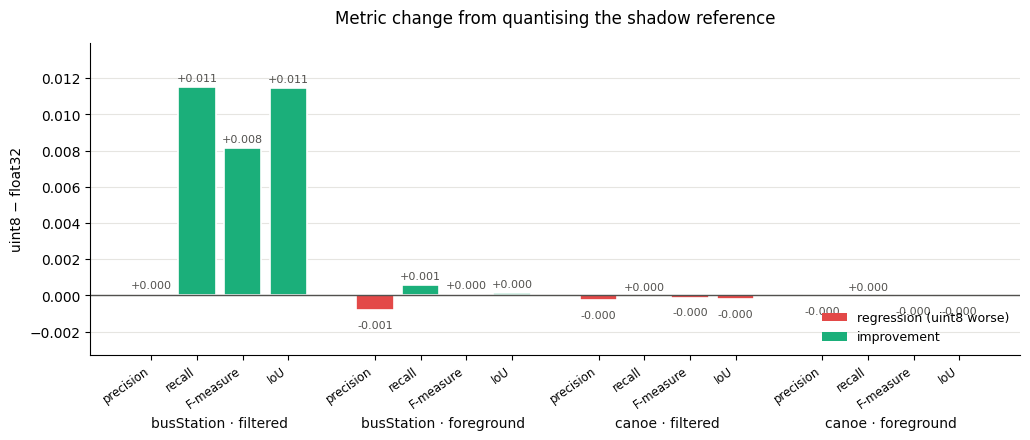

In [22]:
wide = scores.pivot_table(
    index=["case", "mask"], columns="shadow mode",
    values=["precision", "recall", "F-measure", "IoU"],
)
METRICS = ["precision", "recall", "F-measure", "IoU"]
deltas = pd.DataFrame({
    metric: wide[metric]["uint8"] - wide[metric][REFERENCE_MODE] for metric in METRICS
}).reset_index()

display(
    deltas.style.format({m: "{:+.4f}" for m in METRICS})
    .hide(axis="index")
    .background_gradient(subset=METRICS, cmap="RdBu", vmin=-0.10, vmax=0.10)
)

IMPROVED = "#1baf7a"
positions, values, tick_labels, group_centres, group_labels = [], [], [], [], []
cursor = 0.0
for _, row in deltas.iterrows():
    start = cursor
    for metric in METRICS:
        positions.append(cursor)
        values.append(row[metric])
        tick_labels.append(metric)
        cursor += 1.0
    group_centres.append((start + cursor - 1.0) / 2)
    group_labels.append(f"{row['case']} · {row['mask']}")
    cursor += 0.9

values = np.array(values)
fig, ax = plt.subplots(figsize=(12, 5.2))
bars = ax.bar(positions, values, 0.82,
              color=[ONLY_CANDIDATE if v < 0 else IMPROVED for v in values],
              edgecolor="white", linewidth=1.2)
for bar, value in zip(bars, values):
    ax.annotate(f"{value:+.3f}", (bar.get_x() + bar.get_width() / 2, value),
                textcoords="offset points", xytext=(0, 4 if value >= 0 else -13),
                ha="center", fontsize=8, color="#52514e")
ax.axhline(0, color="#52514e", linewidth=1.0)
ax.set_xticks(positions)
ax.set_xticklabels(tick_labels, fontsize=8.5, rotation=35, ha="right")
for centre, label in zip(group_centres, group_labels):
    ax.annotate(label, xy=(centre, 0), xycoords=("data", "axes fraction"),
                xytext=(0, -52), textcoords="offset points",
                ha="center", fontsize=10, color="#0b0b0b", annotation_clip=False)
ax.margins(y=0.20)
ax.set_ylabel(f"uint8 − {REFERENCE_MODE}", fontsize=10)
ax.set_title("Metric change from quantising the shadow reference", fontsize=12, pad=14)
ax.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, facecolor=ONLY_CANDIDATE, edgecolor="none",
                  label="regression (uint8 worse)"),
    plt.Rectangle((0, 0), 1, 1, facecolor=IMPROVED, edgecolor="none",
                  label="improvement"),
], frameon=False, fontsize=9, loc="lower right")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
fig.subplots_adjust(bottom=0.28)
plt.show()

### 4.2 The full-sequence result

Static reference, not recomputed here. Measured over the complete `data/`
sequences at QVGA (1250 and 1570 frames) on the two clips that carry CDNET
shadow labels — `canoe` is excluded because it has none. This is the evidence
the `uint8` mode actually rests on; the tables above are a spot check at 0.1 fps.

| Sequence | Mode | Precision | Recall | F1 | SoL agreement vs `float32` |
| --- | --- | ---: | ---: | ---: | ---: |
| busStation | `off` | 0.8663 | 0.6322 | 0.7310 | 96.16 % |
| busStation | `float32` | 0.8844 | 0.5305 | 0.6632 | — |
| busStation | `uint8` | 0.8840 | 0.5229 | 0.6571 | **99.84 %** |
| traffic | `off` | 0.4877 | 0.8697 | 0.6250 | 94.52 % |
| traffic | `float32` | 0.5238 | 0.8196 | 0.6391 | — |
| traffic | `uint8` | 0.5241 | 0.8179 | 0.6388 | **99.49 %** |

`uint8` vs `float32`: ΔF1 −0.0061 and −0.0002, Sign-of-Life agreement 99.84 %
and 99.49 % — inside the −0.01 / 99 % gate the model quantisation was held to.
Note again that the `off` rows are not evidence about the veto: F1 cannot score
the pixels it exists to remove.

## 5. Per-frame Sign of Life

The pipeline's actual output. One column per frame: a row per arm, plus a row
marking where `uint8` and `float32` disagree.

case,shadow mode,frames,flagged,agreement vs float32
busStation,off,6,3,100.00%
busStation,float32,6,3,100.00%
busStation,uint8,6,3,100.00%
canoe,off,5,1,100.00%
canoe,float32,5,1,100.00%
canoe,uint8,5,1,100.00%


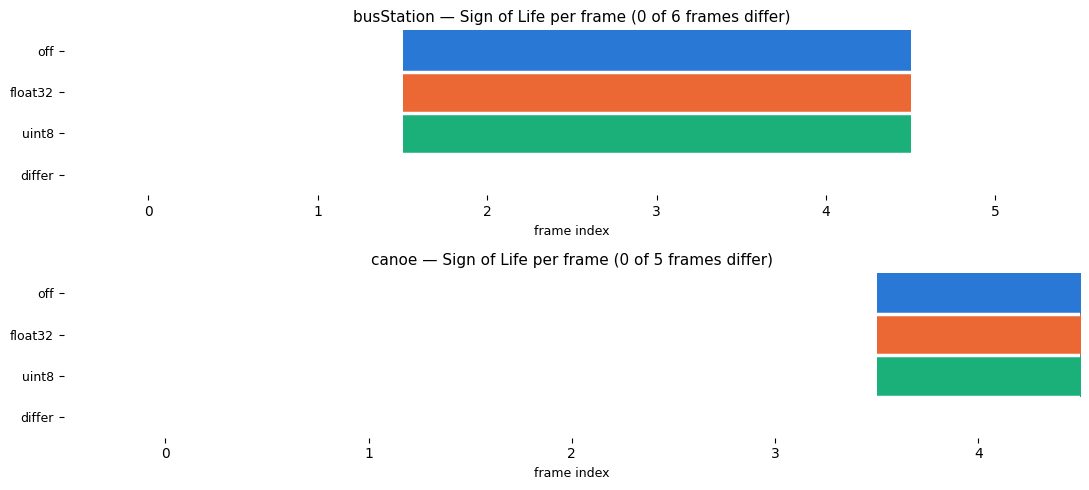

In [23]:
def sol_flags(records: list[dict], mode: str) -> np.ndarray:
    return np.array([bool(r[mode]["sign_of_life"]) for r in records])


rows = []
for case in CASES:
    records = results[case]
    reference = sol_flags(records, REFERENCE_MODE)
    for mode in SHADOW_MODES:
        flags = sol_flags(records, mode)
        rows.append({
            "case": case,
            "shadow mode": mode,
            "frames": len(records),
            "flagged": int(flags.sum()),
            f"agreement vs {REFERENCE_MODE}": float((flags == reference).mean()),
        })
agreement = pd.DataFrame(rows)
display(
    agreement.style.format({f"agreement vs {REFERENCE_MODE}": "{:.2%}"}).hide(axis="index")
)

fig, axes = plt.subplots(len(CASES), 1, figsize=(11, 2.5 * len(CASES)))
axes = np.atleast_1d(axes)
for ax, case in zip(axes, CASES):
    records = results[case]
    flags = {mode: sol_flags(records, mode) for mode in SHADOW_MODES}
    differ = flags["uint8"] != flags[REFERENCE_MODE]
    strip = np.full((len(SHADOW_MODES) + 1, len(records), 3), 255, dtype=np.uint8)
    for row, mode in enumerate(SHADOW_MODES):
        strip[row][flags[mode]] = to_rgb(COLOURS[mode])
    strip[-1][differ] = to_rgb(ONLY_CANDIDATE)
    ax.imshow(strip, aspect="auto", interpolation="nearest")
    for edge in np.arange(len(SHADOW_MODES)) + 0.5:
        ax.axhline(edge, color="white", linewidth=2.5)
    ax.set_yticks(range(len(SHADOW_MODES) + 1))
    ax.set_yticklabels([*SHADOW_MODES, "differ"], fontsize=9)
    ax.set_xlabel("frame index", fontsize=9)
    ax.set_title(f"{case} — Sign of Life per frame "
                 f"({int(differ.sum())} of {len(records)} frames differ)", fontsize=11)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.tight_layout()
plt.show()

## 6. What the choice costs

The reference is the only buffer the veto owns, and the only thing that scales
with the frame. Bytes per pixel are read from the live arrays where a reference
exists, so the figures stay honest if the representation changes again.

`SolPersistentBytes` in the C++ / Alif port is
`w · h · (2 + (veto ? 3 : 0))` bytes plus alignment slack — the `2` is the
background model's quantised mean and variance, and the `3` is this reference.

shadow mode,reference dtype,declared B/px,measured B/px,reference @ QVGA (KB),C++ persistent arena @ QVGA (B)
off,-,0,0.0,0.0,"153,856"
float32,float32,12,12.0,900.0,not implemented
uint8,uint8,3,3.0,225.0,"384,256"


The `float32` row is Python-only: the C++ and Alif ports implement `off` and `uint8` only, so their arena is 153,856 B or 384,256 B. Enabling the veto used to cost 921,600 B and consume essentially the whole SRAM0 headroom; at 230,400 B it leaves ~785 KB free.

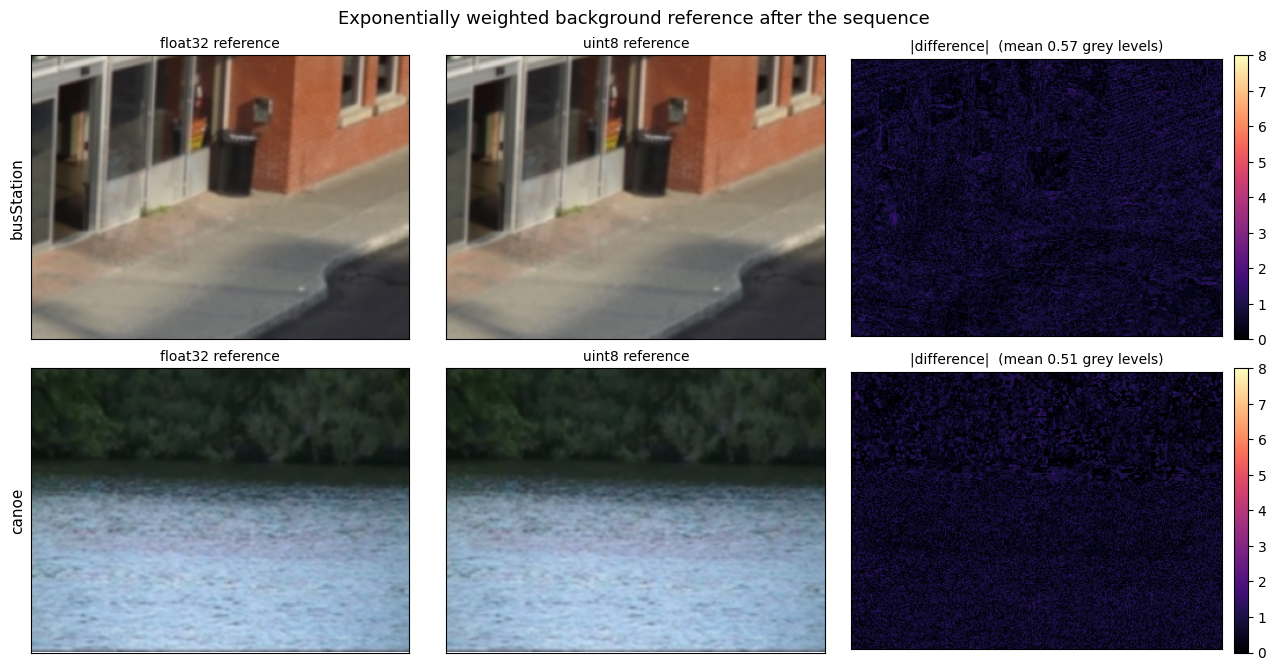

In [24]:
PIXELS_QVGA = 320 * 240


def stored_reference(pipeline):
    """Return the reference as actually stored, or None when the veto is off.

    Deliberate introspection into the model's private state. The public
    ``background_bgr`` renders the reference to uint8 for the veto to consume,
    so it reports 3 B/px whatever the storage is -- measuring it would silently
    claim the float32 arm costs the same as the quantised one.
    """
    return pipeline.model._reference


rows = []
for mode, cfg in SHADOW_MODES.items():
    reference = stored_reference(pipelines[CASES[0]][mode])
    measured = (0.0 if reference is None
                else reference.nbytes / (reference.shape[0] * reference.shape[1]))
    rows.append({
        "shadow mode": mode,
        "reference dtype": "-" if reference is None else str(reference.dtype),
        "declared B/px": cfg.reference_bytes_per_pixel,
        "measured B/px": measured,
        "reference @ QVGA (KB)": cfg.reference_bytes_per_pixel * PIXELS_QVGA / 1024,
        "C++ persistent arena @ QVGA (B)": (
            (2 + (3 if cfg.enabled else 0)) * PIXELS_QVGA + 256
            if mode != "float32" else np.nan
        ),
    })
state = pd.DataFrame(rows)
display(
    state.style.format({
        "measured B/px": "{:.1f}",
        "reference @ QVGA (KB)": "{:.1f}",
        "C++ persistent arena @ QVGA (B)": lambda v: "not implemented" if pd.isna(v) else f"{v:,.0f}",
    }).hide(axis="index")
)

display(Markdown(
    "The `float32` row is Python-only: the C++ and Alif ports implement `off` "
    "and `uint8` only, so their arena is 153,856 B or 384,256 B. Enabling the "
    "veto used to cost 921,600 B and consume essentially the whole SRAM0 "
    "headroom; at 230,400 B it leaves ~785 KB free."
))

fig, axes = plt.subplots(len(CASES), 3, figsize=(13, 3.4 * len(CASES)))
axes = np.atleast_2d(axes)
for r, case in enumerate(CASES):
    backgrounds = {m: pipelines[case][m].model.background_bgr for m in SHADOW_MODES}
    reference = backgrounds[REFERENCE_MODE]
    candidate = backgrounds["uint8"]
    drift = np.abs(reference.astype(np.int16) - candidate.astype(np.int16)).mean(axis=2)
    panels = [
        (reference[:, :, ::-1], f"{REFERENCE_MODE} reference", {}),
        (candidate[:, :, ::-1], "uint8 reference", {}),
        (drift, f"|difference|  (mean {drift.mean():.2f} grey levels)",
         dict(cmap="magma", vmin=0, vmax=8)),
    ]
    for c, (image, title, kwargs) in enumerate(panels):
        ax = axes[r][c]
        rendered = ax.imshow(image, **kwargs)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(title, fontsize=10)
        if c == 0:
            ax.set_ylabel(case, fontsize=11)
        if c == 2:
            fig.colorbar(rendered, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle("Exponentially weighted background reference after the sequence", fontsize=13)
fig.tight_layout()
plt.show()

## Notes

- **What this notebook can and cannot settle.** It can settle `float32` vs
  `uint8`, because both arms veto the same pixels and the metric's blind spot
  cancels between them. It cannot settle whether to run the veto at all — F1
  ignores exactly the pixels the veto targets, so `off` is flattered by
  construction. That question needs a blob-level experiment (does a cast shadow
  push a person's region past `area_threshold`?), not a pixel metric.
- **Sequence length dominates on this tree.** Five or six frames at α = 0.1
  leaves the EW reference close to the frame it was seeded from, so the two veto
  arms have had little chance to diverge. Section 4.2 is the real evidence.
- **The veto is under-validated at any dtype.** There is no CDNET *shadow*
  category clip in the local tree; `busStation` and `traffic` carry shadow
  labels incidentally, and `canoe` has none. Quantising the reference did not
  create that gap and does not close it.
- **The ports carry only `off` and `uint8`.** `float32` exists in Python for
  this comparison. Python's `uint8` mode is bit-identical to the C++
  `ShadowSuppressor`, verified over 60 frames, so what is measured here is what
  the device runs.
- **`ALPHA` is a correctness parameter for both quantised stages.** Below
  ≈0.071 the dead zone exceeds what either the model mean or the reference can
  tolerate; `SignOfLifeDetector::Init()` rejects it and the Python model warns.